# 05. Спектр изображения и метод Фурье

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** вывести боковые полосы спектра, извлечь комплексное поле и понять ограничения несущей.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Что делает преобразование Фурье

DFT раскладывает N отсчётов по комплексным гармоникам:
$$F_k=\sum_{j=0}^{N-1}f_j e^{-2\pi i jk/N},\qquad
f_j=\frac1N\sum_{k=0}^{N-1}F_k e^{2\pi i jk/N}.$$
Скалярное произведение с гармоникой измеряет её присутствие в сигнале.
FFT — быстрый алгоритм вычисления той же DFT, а не другая математическая операция.
Для вещественного сигнала $F(-f)=F(f)^*$: положительная и отрицательная частоты
содержат сопряжённые сведения. Выбор стороны задаёт соглашение о знаке фазы.

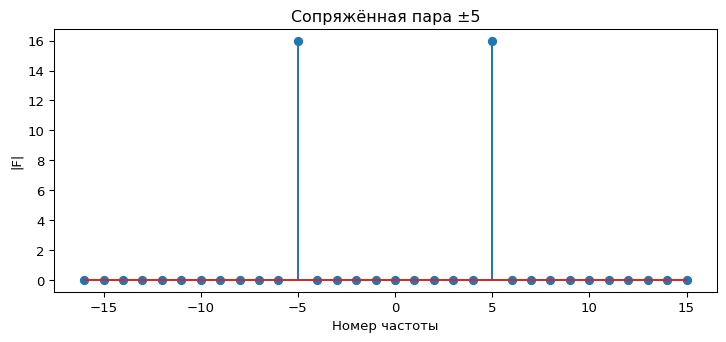

In [2]:
N=32
j=np.arange(N)
data=np.cos(2*np.pi*5*j/N+.7)
matrix=np.exp(-2j*np.pi*np.outer(j,j)/N)
direct=matrix@data
fast=np.fft.fft(data)
assert np.allclose(direct,fast,atol=1e-12)
plt.stem(np.fft.fftfreq(N)*N,np.abs(fast))
plt.xlabel('Номер частоты'); plt.ylabel('|F|'); plt.title('Сопряжённая пара ±5')
plt.show()

## 2. От косинуса к боковым спектральным полосам

Выделим несущую: $\varphi=2\pi\mathbf f_0\cdot\mathbf x+\psi(\mathbf x)$.
Положим $c(\mathbf x)=\frac12 b(\mathbf x)e^{i\psi(\mathbf x)}$.
Тогда
$$I=a+c\,e^{2\pi i\mathbf f_0\cdot\mathbf x}
+c^*e^{-2\pi i\mathbf f_0\cdot\mathbf x}.$$
По теореме сдвига умножение на гармонику переносит спектр:
$$\widehat I(\mathbf f)=A(\mathbf f)+C(\mathbf f-\mathbf f_0)
+C^*(-\mathbf f-\mathbf f_0).$$

Если спектры разделены, оставляем одну боковую полосу. Обратная FFT даёт комплексное
поле, аргумент которого содержит фазу. Это и есть основа пространственно-несущего
метода Такеды. Необходимы достаточная несущая, разрешение камеры и отсутствие
опасного перекрытия полос. Чистый набор концентрических колец этим допущениям
в общем случае не удовлетворяет.

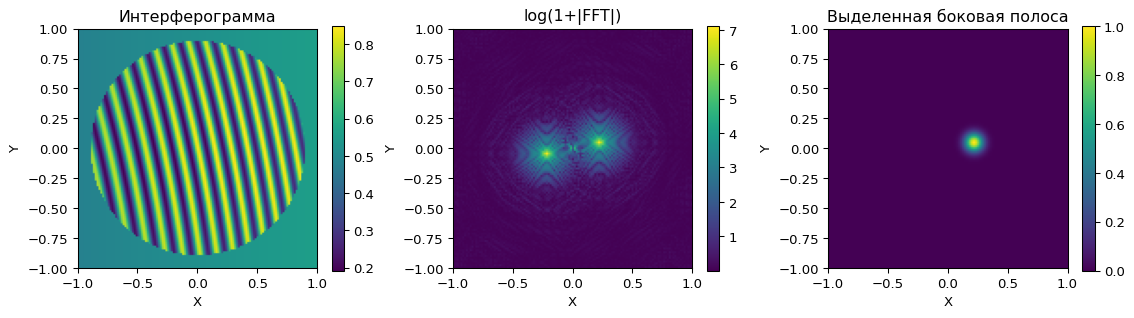

Выбранная несущая, cycles/pixel: (np.float64(0.10852713178294573), np.float64(0.023255813953488372))


In [3]:
s=cl.scene(n=129,carrier_x=14,carrier_y=3,bowl=.35)
result=cl.fourier_phase(s['image'],s['mask'])
cl.show_maps([s['image'],np.log1p(np.abs(result['spectrum'])),result['window']],
             ['Интерферограмма','log(1+|FFT|)','Выделенная боковая полоса'])
print('Выбранная несущая, cycles/pixel:',result['frequency'])

## 3. Демодуляция и возвращение наклона

Выделенное комплексное поле имеет вид $z\approx c\,e^{2\pi i\mathbf f_0\cdot x}$.
Для удобной развёртки можно умножить его на обратную несущую:
$z_0=z e^{-2\pi i\mathbf f_0\cdot x}$. Тогда аргумент z₀ — медленная остаточная фаза.
После развёртки добавляем несущую обратно. Иначе можно незаметно потерять наклон.

`fftshift` только переставляет индексы для размещения DC в центре.
Для обратного перехода нужен `ifftshift`; на нечётной сетке эти перестановки различны.
Обмен четырёх равных квадрантов корректен лишь для соответствующего чётного размера.

128 {'rms': 0.0002802950320585331, 'pv': 0.0013520576857271038, 'bias': 8.005681655255152, 'coverage': 1.0}
129 {'rms': 0.0002786153137790665, 'pv': 0.001362385217465345, 'bias': 8.00568291535139, 'coverage': 1.0}


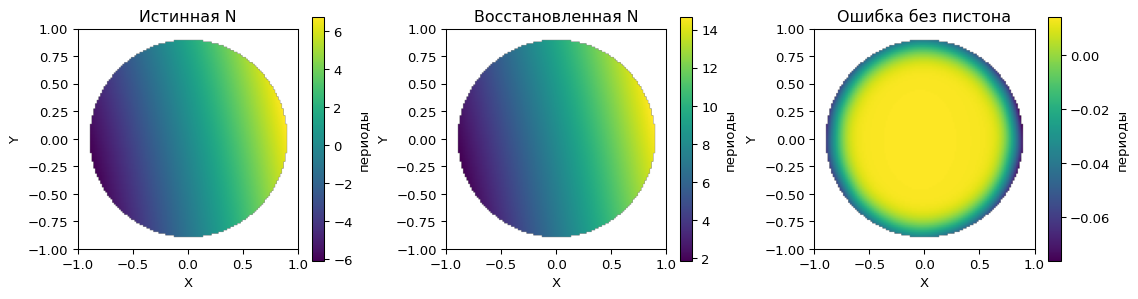

In [4]:
for n in [128,129]:
    data=np.arange(n)
    assert np.array_equal(np.fft.ifftshift(np.fft.fftshift(data)),data)
    sample=cl.scene(n=n,carrier_x=14,carrier_y=3,bowl=.35)
    reconstructed=cl.fourier_phase(sample['image'],sample['mask'])
    roi=sample['mask'] & (sample['x']**2+sample['y']**2<.55**2)
    error,stats=cl.compare(reconstructed['phi']/cl.TAU,sample['orders'],roi)
    print(n,stats)
error,stats=cl.compare(result['phi']/cl.TAU,s['orders'],s['mask'])
cl.show_maps([s['orders'],result['phi']/cl.TAU,error],['Истинная N','Восстановленная N','Ошибка без пистона'],s['mask'],units='периоды')

## 4. Фильтр — компромисс разрешения и подавления помех

Слишком узкое окно срезает быстрые изменения ψ: карта становится красивее и
глаже, но теряет детали. Слишком широкое захватывает фон и сопряжённую полосу.
Ошибка может расти и без шума. Определение «лучшего» окна зависит от спектра
измеряемого фронта и требуемого пространственного разрешения.

Умножение изображения на маску соответствует свёртке спектров. Резкая граница
апертуры расширяет спектр; аподизация смягчает границу, одновременно ослабляя
измерения у края. Поэтому центральная ошибка и ошибка всего поля различаются.
В учебной функции маска и амплитуда используются для отбора валидных точек,
а развёртка начинает обход только в этих точках.

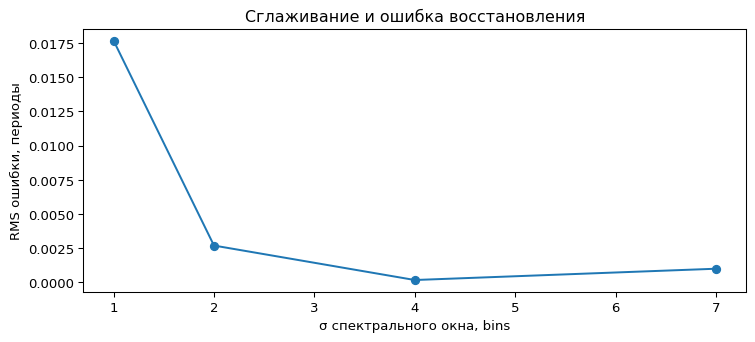

Однотонное изображение отклонено: Нет измеримого контраста


In [5]:
widths=[1.0,2.0,4.0,7.0]
errors=[]
roi=s['mask']&(s['x']**2+s['y']**2<.55**2)
for width in widths:
    reconstructed=cl.fourier_phase(s['image'],s['mask'],sigma_bins=width)
    errors.append(cl.compare(reconstructed['phi']/cl.TAU,s['orders'],roi)[1]['rms'])
plt.plot(widths,errors,'o-'); plt.xlabel('σ спектрального окна, bins'); plt.ylabel('RMS ошибки, периоды')
plt.title('Сглаживание и ошибка восстановления'); plt.show()
try:
    cl.fourier_phase(np.ones((64,64)),np.ones((64,64),bool))
except ValueError as error:
    print('Однотонное изображение отклонено:',error)

## Задания

1. Уменьшайте carrier_x при фиксированной чаше. Где разделение полос перестаёт быть убедительным?
2. Замените n=128 на 129. Почему математический метод не должен резко терять точность?
3. Уберите возвращение несущей из учебной реализации. Какой коэффициент S5 изменится?
4. Почему выбор положительной полуплоскости не доказывает знак физической высоты?

<details><summary>Разбор</summary>

Несущая должна отделять изменяющееся комплексное поле от DC и сопряжения.
Разница чётности требует правильных перестановок FFT, а не изменения физики.
Потеряется линейный наклон. Интенсивности cos φ и cos(−φ) одинаковы;
физическое направление OPD требует внешнего соглашения или калиброванного сдвига.
</details>

**Чтение:** [Takeda–Ina–Kobayashi, 1982](https://doi.org/10.1364/JOSA.72.000156).
**В проекте:** `plugin-sdk/fourier_phase_plugin/plugin.cpp`. Сравните выбор маски
выхода, стартовой точки и спектрального окна; учебная функция не является портом DLL.
Далее: [вейвлеты](06_wavelets.ipynb).